# Indian Stock Price EDA: Reliance, TCS and Infosys

Exploratory analysis of one year of daily NSE closing prices (25 Sep 2025 to 25 Sep 2026)
for three large Indian companies. For each stock we measure:

- daily returns
- volatility (overall and 30-day rolling)
- maximum drawdown
- total return, compared on a normalized scale

## 1. Import Required Libraries

We use pandas for data manipulation and matplotlib for charts.
yfinance is only needed if you choose to download fresh data (see the next section).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## 2. Load the Price Data

The closing prices were downloaded once from Yahoo Finance with `yfinance` and saved to
`data/prices.csv`, so the notebook gives the same results every time it is run.

Set `DOWNLOAD_FRESH_DATA = True` to download the same date range again and overwrite the file.
Yahoo Finance sometimes revises its history, so a fresh download can differ slightly from the saved file.

In [2]:
# Yahoo Finance tickers; the .NS suffix means the NSE-listed share.
TICKERS = {"Reliance": "RELIANCE.NS", "TCS": "TCS.NS", "Infosys": "INFY.NS"}
DATA_FILE = "data/prices.csv"
DOWNLOAD_FRESH_DATA = False

if DOWNLOAD_FRESH_DATA:
    import yfinance as yf

    raw = yf.download(list(TICKERS.values()), start="2025-09-25", end="2026-09-26")
    raw["Close"][list(TICKERS.values())].to_csv(DATA_FILE)

prices = pd.read_csv(DATA_FILE, index_col="Date", parse_dates=True)

# Use company names instead of ticker symbols as column names.
prices = prices.rename(columns={ticker: name for name, ticker in TICKERS.items()})

## 3. Inspect the Data

Each row is one trading day and each column holds that stock's closing price in rupees.

In [3]:
prices.head()

,Reliance,TCS,Infosys
Date,,,
2025-09-25,1366.083862,2824.508057,1431.436890
2025-09-26,1371.259888,2768.827881,1396.827026
2025-09-29,1366.481934,2765.962891,1389.982178
2025-09-30,1357.722412,2758.608887,1389.982178
2025-10-01,1362.400757,2783.249268,1393.838501


In [4]:
prices.shape

(248, 3)

In [5]:
# Check data types and confirm there are no missing values.
prices.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 248 entries, 2025-09-25 to 2026-09-25
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Reliance  248 non-null    float64
 1   TCS       248 non-null    float64
 2   Infosys   248 non-null    float64
dtypes: float64(3)
memory usage: 7.8 KB


## 4. Daily Returns

The daily return is the percentage change in closing price from one trading day to the next:

`Return_t = Price_t / Price_(t-1) - 1`

The first row is empty because there is no previous day to compare with.

In [6]:
returns = prices.pct_change()
returns.head()

,Reliance,TCS,Infosys
Date,,,
2025-09-25,NaN,NaN,NaN
2025-09-26,0.003789,-0.019713,-0.024178
2025-09-29,-0.003484,-0.001035,-0.004900
2025-09-30,-0.006410,-0.002659,0.000000
2025-10-01,0.003446,0.008932,0.002774


In [7]:
# Summary statistics: average return, spread, and the most extreme days.
returns.describe()

,Reliance,TCS,Infosys
count,247.000000,247.000000,247.000000
mean,-0.000353,-0.001094,-0.001271
std,0.013050,0.017953,0.018962
min,-0.045998,-0.083861,-0.072585
25%,-0.008389,-0.009095,-0.011194
50%,-0.000329,-0.001035,-0.002329
75%,0.006298,0.008761,0.007950
max,0.035291,0.065074,0.056798


### Best and Worst Trading Days

`idxmax()` gives the date of the highest return and `idxmin()` the date of the lowest.

In [8]:
extremes = pd.DataFrame({
    "Best Day": returns.idxmax(),                # date of the highest daily return
    "Best Return (%)": returns.max() * 100,      # the highest daily return
    "Worst Day": returns.idxmin(),               # date of the lowest daily return
    "Worst Return (%)": returns.min() * 100,     # the lowest daily return
})
extremes

,Best Day,Best Return (%),Worst Day,Worst Return (%)
Reliance,2025-10-20,3.529072,2026-03-27,-4.599813
TCS,2026-06-02,6.507363,2026-06-03,-8.386125
Infosys,2026-06-02,5.679839,2026-02-04,-7.258455


## 5. Volatility

Volatility is the standard deviation of daily returns: the higher it is, the more the
price moved around from day to day.

In [9]:
volatility = returns.std()
volatility * 100

Reliance    1.304995
TCS         1.795306
Infosys     1.896190
dtype: float64

### 30-Day Rolling Volatility

A rolling window over the most recent 30 trading days shows how volatility changed over time.

In [10]:
rolling_volatility = returns.rolling(30).std()

# Highest 30-day volatility reached by each stock.
rolling_volatility.max() * 100

Reliance    1.960462
TCS         2.854113
Infosys     2.770556
dtype: float64

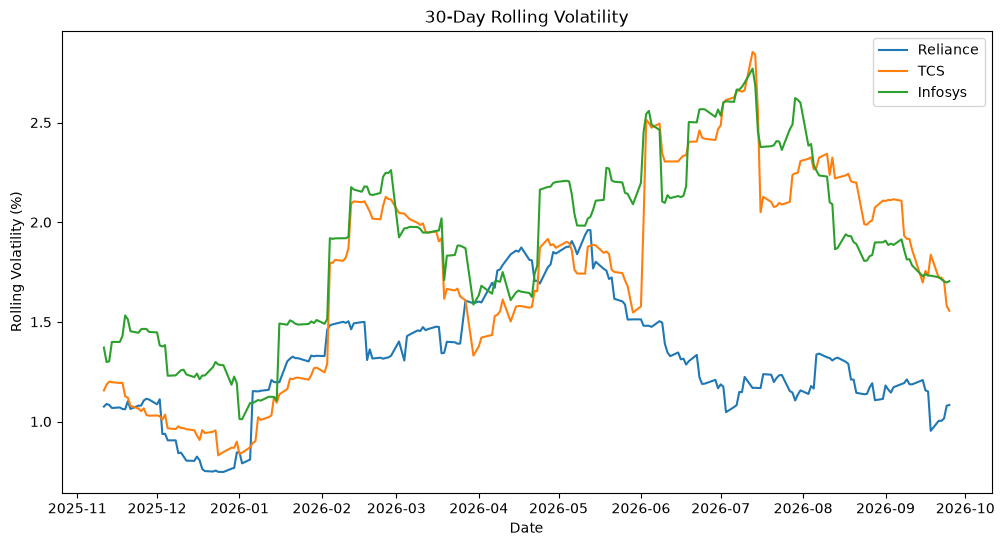

In [11]:
plt.figure(figsize=(12, 6))
for stock in prices.columns:
    plt.plot(rolling_volatility[stock] * 100, label=stock)

plt.title("30-Day Rolling Volatility")
plt.xlabel("Date")
plt.ylabel("Rolling Volatility (%)")
plt.legend()
plt.show()

## 6. Maximum Drawdown

Drawdown measures how far the price is below its highest close so far:

`Drawdown_t = (Price_t - Peak_t) / Peak_t`

The maximum drawdown is the most negative value, i.e. the largest peak-to-trough fall.

In [12]:
# Highest closing price reached up to each trading day.
peak = prices.cummax()
drawdown = (prices - peak) / peak

max_drawdown = drawdown.min()
max_drawdown * 100

Reliance   -23.077499
TCS        -38.463943
Infosys    -40.429562
dtype: float64

In [13]:
# Date on which each stock was furthest below its previous peak.
drawdown.idxmin()

Reliance   2026-09-24
TCS        2026-07-01
Infosys    2026-07-01
dtype: datetime64[us]

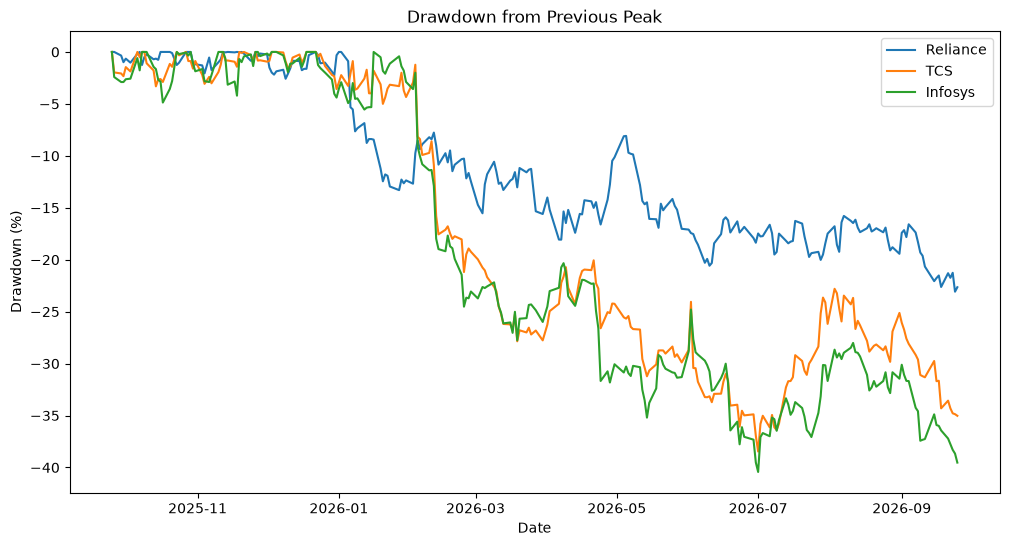

In [14]:
plt.figure(figsize=(12, 6))
for stock in prices.columns:
    plt.plot(drawdown[stock] * 100, label=stock)

plt.title("Drawdown from Previous Peak")
plt.xlabel("Date")
plt.ylabel("Drawdown (%)")
plt.legend()
plt.show()

## 7. Total Return and Normalized Performance

The three stocks trade at very different prices, so we rescale each one to start at 100.
The final value shows what ₹100 invested on the first day would be worth at the end,
ignoring dividends, taxes, brokerage and other costs.

In [15]:
normalized = prices / prices.iloc[0] * 100
total_return = prices.iloc[-1] / prices.iloc[0] - 1

normalized.iloc[-1]

Reliance    89.745588
TCS         73.322166
Infosys     69.873846
Name: 2026-09-25 00:00:00, dtype: float64

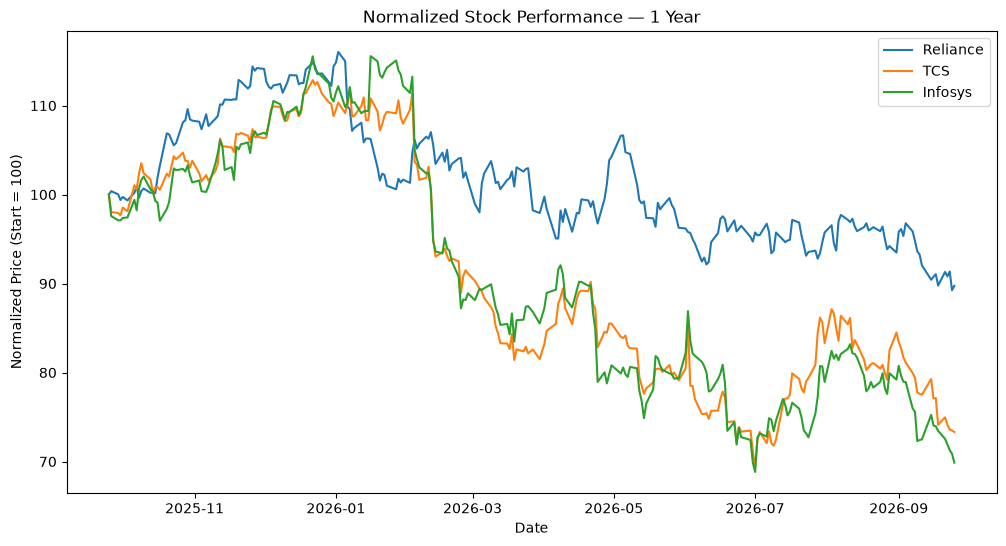

In [16]:
plt.figure(figsize=(12, 6))
for stock in prices.columns:
    plt.plot(normalized[stock], label=stock)

plt.title("Normalized Stock Performance — 1 Year")
plt.xlabel("Date")
plt.ylabel("Normalized Price (Start = 100)")
plt.legend()
plt.savefig("outputs/normalized_performance.png", dpi=300, bbox_inches="tight")
plt.show()

## 8. Comparison of the Three Stocks

All the metrics side by side, in percent.

In [17]:
final_comparison = pd.DataFrame({
    "Total Return (%)": total_return * 100,
    "Average Daily Return (%)": returns.mean() * 100,
    "Volatility (%)": volatility * 100,
    "Best Day (%)": returns.max() * 100,
    "Worst Day (%)": returns.min() * 100,
    "Maximum Drawdown (%)": max_drawdown * 100,
})
final_comparison.index.name = "Stock"

final_comparison.to_csv("outputs/stock_comparison.csv")
final_comparison.round(2)

,Total Return (%),Average Daily Return (%),Volatility (%),Best Day (%),Worst Day (%),Maximum Drawdown (%)
Stock,,,,,,
Reliance,-10.25,-0.04,1.3,3.53,-4.60,-23.08
TCS,-26.68,-0.11,1.8,6.51,-8.39,-38.46
Infosys,-30.13,-0.13,1.9,5.68,-7.26,-40.43


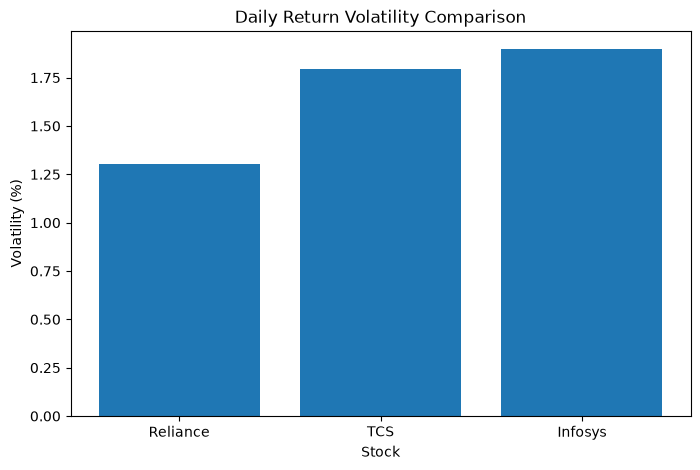

In [18]:
plt.figure(figsize=(8, 5))
plt.bar(final_comparison.index, final_comparison["Volatility (%)"])

plt.title("Daily Return Volatility Comparison")
plt.xlabel("Stock")
plt.ylabel("Volatility (%)")
plt.savefig("outputs/volatility_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

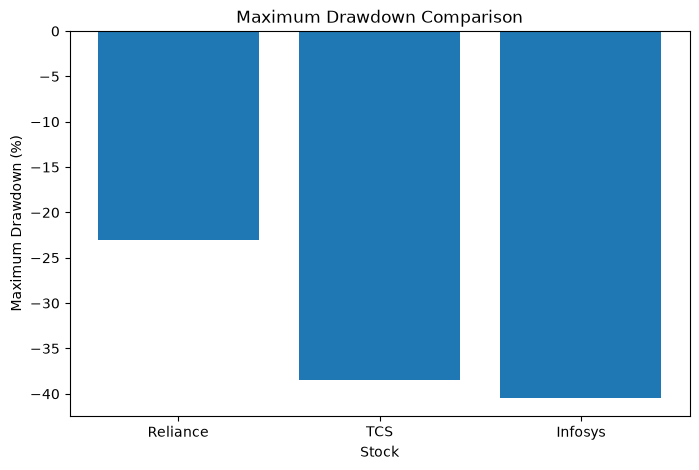

In [19]:
plt.figure(figsize=(8, 5))
plt.bar(final_comparison.index, final_comparison["Maximum Drawdown (%)"])

plt.title("Maximum Drawdown Comparison")
plt.xlabel("Stock")
plt.ylabel("Maximum Drawdown (%)")
plt.savefig("outputs/drawdown_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

## Conclusion

### Overall Performance

- Analysed 248 trading days of daily closing prices (25 Sep 2025 to 25 Sep 2026) for Reliance Industries, TCS and Infosys.
- All three stocks recorded negative total returns over the period:
  - Reliance: -10.25%
  - TCS: -26.68%
  - Infosys: -30.13%

### Daily Returns and Volatility

- Daily volatility was 1.30% for Reliance, 1.80% for TCS and 1.90% for Infosys.
- The largest positive daily move was +6.51% (TCS).
- The largest negative daily move was -8.39% (TCS).
- Individual trading days saw considerable price movements.

### Maximum Drawdown

- Reliance: -23.08%
- TCS: -38.46%
- Infosys: -40.43%
- Drawdown shows how far each stock fell from a previous closing-price peak during the period.

### Key Inferences

- Total return, volatility and drawdown describe different aspects of stock behaviour:
  - total return measures the overall price change,
  - volatility measures how much daily returns varied,
  - drawdown measures the decline from a previous peak.
- Looking at these metrics together gives a more complete view of historical performance and risk.
- Reliance had the lowest volatility of the three, yet it still fell 23% from its peak: low daily volatility does not rule out a large decline.

### Limitations

- Only about one year of data and three stocks were analysed.
- The analysis looks at price behaviour only.
- Dividends, taxes, brokerage charges and transaction costs are not included in the simple price return.
- Historical results do not guarantee future performance.

### Final Note

These findings are historical observations for the selected stocks and period. They are not predictions of future performance or investment advice.